# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:**
- **Устройство:** локально, NVIDIA GeForce RTX 2060 6 ГБ, Ryzen 5 7500F, Windows 11, Python 3.13, torch 2.12.0+cu126, ultralytics 8.4.53.
- **Модель:** `yolo26n.pt` (COCO), sha256 и остальное - в `MODEL_INFO` (1.1).
- **Датасет:** [Garbage Detection v8](https://universe.roboflow.com/garbage-detection-zgdc2/garbage-detection-pbcjq), Roboflow Universe, лицензия CC BY 4.0. Скачивается в 2.1 через Roboflow API (экспорт COCO), нужен бесплатный ключ: переменная окружения `ROBOFLOW_API_KEY` или строка `ROBOFLOW_API_KEY=...` в `.env` (в репозиторий не кладется). Если `data/garbage` уже есть, скачивание пропускается.
- **Бонусы:** 6.2, 6.3, 6.4, 6.5.
- **Источники:** документация ultralytics (train/val/export, таблица YOLO26), структура задания и семинар 5-6.
- **Отклонения:** RT-DETR (6.2) обучен при imgsz 320 и 10 эпохах: при 640 даже с batch 2 он не помещается в 6 ГБ видеопамяти (уходит в общую память, ~1.6 с на итерацию). Нерешенных задач в обязательной части нет, 6.1 не делал.

In [1]:
import os
os.environ.setdefault('YOLO_VERBOSE', 'False')   # до импорта ultralytics: без его логов и прогресс-баров, метрики печатаем сами
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.53, torch 2.12.0+cu126, device: NVIDIA GeForce RTX 2060


In [2]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}     # например {'6.3', '6.5'}; пустое множество пропускает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter могут зависать
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = 'yolo26n.pt'   # свой выбор, можно поменять и обосновать
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
N_WARMUP_RUNS = 5
N_LATENCY_RUNS = 30


def synchronize(device):
    if device not in ('cpu', 'mps') and torch.cuda.is_available():
        torch.cuda.synchronize()


def measure_latency_ms(model, imgsz, device=DEVICE, **predict_kwargs):
    # end-to-end задержка predict (препроцессинг + сеть + постпроцессинг) на одной картинке, после прогрева
    image = np.random.default_rng(SEED).integers(0, 256, (imgsz, imgsz, 3), dtype=np.uint8)
    for _ in range(N_WARMUP_RUNS):
        model.predict(image, imgsz=imgsz, device=device, verbose=False, **predict_kwargs)
    timings = []
    for _ in range(N_LATENCY_RUNS):
        synchronize(device)
        start = time.perf_counter()
        model.predict(image, imgsz=imgsz, device=device, verbose=False, **predict_kwargs)
        synchronize(device)
        timings.append(time.perf_counter() - start)
    return 1000 * float(np.mean(timings))


n_params_coco = sum(p.numel() for p in model_coco.model.parameters())   # до predict: потом Conv и BN сольются
MODEL_INFO = dict(
    ultralytics=ultralytics.__version__,
    weights=WEIGHTS,
    sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
    size_mb=round(weights_path.stat().st_size / 2**20, 2),
    params=n_params_coco,
    n_classes_coco=len(model_coco.names),
    latency_ms=measure_latency_ms(model_coco, IMGSZ),
    latency_device=DEVICE_NAME,
    latency_imgsz=IMGSZ,
)

In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.53',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.29,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 8.775746655495217,
 'latency_device': 'NVIDIA GeForce RTX 2060',
 'latency_imgsz': 640}

**Ответ:** Взял n: 60 эпох при 640 заняли 63 мин на RTX 2060 (batch 16, до 2.9 ГБ), примерно в бюджет. По таблице документации s в ~4 раза больше (9.5M против 2.4M параметров) и точнее на COCO (mAP50-95 48.6 против 40.9), но медленнее: 2.5 против 1.7 мс на T4 TensorRT, 87 против 39 мс на CPU ONNX, и за час прошла бы заметно меньше эпох. Для одного класса с крупными объектами запас емкости s, скорее всего, не нужен. Мои 8.8 мс больше табличных 1.7, потому что это полный `predict` с пре- и постобработкой в PyTorch на RTX 2060, а в таблице только сеть на TensorRT.

Код и веса ultralytics под AGPL-3.0: если распространяешь программу с ними или даешь к ней доступ по сети, обязан открыть исходники всего проекта под AGPL. Для закрытого коммерческого продукта нужна платная Enterprise-лицензия.

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def count_params(modules):
    return sum(p.numel() for module in modules for p in module.parameters())


def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    return dict(backbone=count_params(layers[:n_backbone]),
                neck=count_params(layers[n_backbone:-1]),
                head=count_params(layers[-1:]))


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    captured = {}

    def remember_inputs(module, inputs):
        # pre-hook, а не обычный hook: Detect может переписать список входов на месте во время forward
        captured['feats'] = [tuple(feature.shape) for feature in inputs[0]]

    handle = det_model.model[-1].register_forward_pre_hook(remember_inputs)
    was_training = det_model.training
    det_model.eval()
    try:
        with torch.no_grad():
            device = next(det_model.parameters()).device
            output = det_model(torch.zeros(1, 3, imgsz, imgsz, device=device))
    finally:
        handle.remove()
        det_model.train(was_training)
    return captured['feats'], output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
print('Выход модели (eval):')
for key, value in zip(('decoded (top-300: x1 y1 x2 y2 score cls)', 'raw'), out):
    print(f'  {key}: {shapes(value)}')

n_backbone = len(arch.yaml['backbone'])
print(f'\n{"#":>2} {"блок":<8} {"слой":<9} {"from":<12} {"params":>9}')
for index, layer in enumerate(arch.model):
    block = 'backbone' if index < n_backbone else ('head' if index == len(arch.model) - 1 else 'neck')
    print(f'{index:>2} {block:<8} {type(layer).__name__:<9} {str(layer.f):<12} {count_params([layer]):>9,}')
n_anchor_points = sum(h * w for *_, h, w in feat_shapes)
print(f'\nточек на картах признаков при 640: {" + ".join(f"{h}x{w}" for *_, h, w in feat_shapes)} = {n_anchor_points}')

Выход модели (eval):
  decoded (top-300: x1 y1 x2 y2 score cls): (1, 300, 6)
  raw: {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}

 # блок     слой      from            params
 0 backbone Conv      -1                 464
 1 backbone Conv      -1               4,672
 2 backbone C3k2      -1               6,640
 3 backbone Conv      -1              36,992
 4 backbone C3k2      -1              26,080
 5 backbone Conv      -1             147,712
 6 backbone C3k2      -1              87,040
 7 backbone Conv      -1             295,424
 8 backbone C3k2      -1             346,112
 9 backbone SPPF      -1             164,608
10 backbone C2PSA     -1             249,728
11 neck     Upsample  -1                   0
12 neck     Concat    [-1, 6]              0
13 neck     C3k2      -1         

**Ответ:** Backbone (слои 0-10, 1.37M параметров, 53%) извлекает признаки: Conv со stride 2 уменьшают картинку вдвое, C3k2 (CSP-блоки) строят признаки, SPPF расширяет рецептивное поле, C2PSA добавляет self-attention на самой грубой карте. Наружу идут карты stride 8, 16, 32 (слои 4, 6, 10).

Neck (слои 11-22, 0.90M, 35%) - PAN-FPN: сверху вниз P5 апсемплится и склеивается с P4 и P3 (мелкие карты получают семантику), снизу вверх P3 даунсемплится и склеивается с P4 и P5 (грубые получают точную локализацию). В Detect приходят карты 80x80, 40x40, 20x20 с 64, 128, 256 каналами.

Head (Detect, 0.31M, 12%) в каждой точке предсказывает 4 расстояния от точки до сторон бокса и 80 скоров классов, без objectness. У YOLO26 `reg_max=1`, DFL убран: на бокс 4 канала вместо 4x16 (лосс в логах все равно называется `dfl_loss`). Anchor-free - потому что нет заранее заданных якорных боксов, бокс регрессируется прямо от точки сетки. 8400 = 80² + 40² + 20² точек при stride 8/16/32.

one2many и one2one - две одинаковые головы. one2many при обучении назначает на объект до 10 положительных точек: градиент богаче, но на выходе дубли, нужен NMS. one2one учится давать на объект одно предсказание, дублей нет, поэтому в eval из нее просто берется top-300 по скору (выход `(1, 300, 6)`). Лоссы веток складываются, но one2one получает признаки через `detach`, так что backbone и neck учит в основном one2many.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
import io
import zipfile
import requests

DATASET_NAME = ('Garbage Detection v8 (Roboflow Universe, '
                'https://universe.roboflow.com/garbage-detection-zgdc2/garbage-detection-pbcjq, CC BY 4.0)')
RF_EXPORT_URL = 'https://api.roboflow.com/garbage-detection-zgdc2/garbage-detection-pbcjq/8/coco'
RAW_ROOT = DATA_ROOT / 'garbage'
SOURCE_SPLITS = ('train', 'valid', 'test')
SPLIT_FRACTIONS = dict(val=0.2, test=0.2)   # доли групп-фотографий, остальное - train
HTTP_RETRIES = 8
MIN_BOX_SIDE = 1.0   # px: бокс уже - вырожденный, выбрасываем


def read_api_key():
    # ключ не в ноутбуке: переменная окружения или строка ROBOFLOW_API_KEY=... в .env (он в .gitignore)
    if os.environ.get('ROBOFLOW_API_KEY'):
        return os.environ['ROBOFLOW_API_KEY']
    for env_file in (Path('.env'), Path('..') / '.env'):
        if not env_file.exists():
            continue
        for line in env_file.read_text(encoding='utf-8').splitlines():
            name, _, value = line.partition('=')
            if name.strip() == 'ROBOFLOW_API_KEY':
                return value.strip().strip('"\'')
    raise RuntimeError('Нужен бесплатный ключ Roboflow: export ROBOFLOW_API_KEY=... или строка в .env')


def get_with_retries(url, **kwargs):
    # api.roboflow.com периодически рвет TLS-соединение (ConnectionResetError), повтор помогает
    for attempt in range(HTTP_RETRIES):
        try:
            response = requests.get(url, timeout=600, **kwargs)
            response.raise_for_status()
            return response
        except requests.ConnectionError:
            if attempt == HTTP_RETRIES - 1:
                raise
            time.sleep(2)


def download_dataset():
    if (RAW_ROOT / 'train' / '_annotations.coco.json').exists():
        return
    export = get_with_retries(RF_EXPORT_URL, params={'api_key': read_api_key()}).json()['export']
    archive = get_with_retries(export['link']).content
    with zipfile.ZipFile(io.BytesIO(archive)) as zip_file:
        zip_file.extractall(RAW_ROOT)


def original_name(file_name):
    # Roboflow называет файлы <исходное имя>_<расширение>.rf.<хеш>.jpg; копии одного фото делят префикс
    return file_name.split('.rf.')[0]


def coco_to_xyxy(bbox, width, height):
    x, y, w, h = bbox
    box = np.array([x, y, x + w, y + h], dtype=np.float64)
    clipped = np.clip(box, 0, [width, height, width, height])
    return clipped, not np.allclose(box, clipped)


def load_coco_split(split, class_index, stats):
    coco = json.loads((RAW_ROOT / split / '_annotations.coco.json').read_text(encoding='utf-8'))
    annotations = {}
    for ann in coco['annotations']:
        annotations.setdefault(ann['image_id'], []).append(ann)
    recs = []
    for image in coco['images']:
        boxes, labels = [], []
        for ann in annotations.get(image['id'], []):
            box, was_clipped = coco_to_xyxy(ann['bbox'], image['width'], image['height'])
            stats['clipped'] += was_clipped
            if min(box[2] - box[0], box[3] - box[1]) < MIN_BOX_SIDE:
                stats['degenerate'] += 1
                continue
            boxes.append(box)
            labels.append(class_index[ann['category_id']])
        recs.append(dict(image=RAW_ROOT / split / image['file_name'], width=image['width'], height=image['height'],
                         boxes=np.array(boxes, dtype=np.float64).reshape(-1, 4), labels=np.array(labels, dtype=np.int64),
                         group=original_name(image['file_name']), source_split=split))
    return recs


def read_classes():
    # в COCO-экспорте Roboflow категория с supercategory 'none' - заглушка-родитель, объектов у нее нет
    categories = json.loads((RAW_ROOT / 'train' / '_annotations.coco.json').read_text(encoding='utf-8'))['categories']
    real = [c for c in categories if c['supercategory'] != 'none']
    return [c['name'] for c in real], {c['id']: k for k, c in enumerate(real)}


def group_split(all_recs, seed=SEED):
    # сплит по исходным фото: все аугментированные копии фото попадают в один сплит.
    # В val/test оставляем одну случайную копию на фото, чтобы одно фото не считалось 3 раза
    groups = sorted({r['group'] for r in all_recs})
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(groups))
    n_val, n_test = (round(SPLIT_FRACTIONS[s] * len(groups)) for s in ('val', 'test'))
    split_of = {groups[i]: 'val' for i in order[:n_val]}
    split_of.update({groups[i]: 'test' for i in order[n_val:n_val + n_test]})
    by_group = {}
    for r in all_recs:
        by_group.setdefault(r['group'], []).append(r)
    result = {'train': [], 'val': [], 'test': []}
    for group in groups:
        copies = by_group[group]
        split = split_of.get(group, 'train')
        result[split].extend(copies if split == 'train' else [copies[rng.integers(len(copies))]])
    return result


download_dataset()
CLASSES, coco_class_index = read_classes()
clean_stats = Counter()
raw_records = {split: load_coco_split(split, coco_class_index, clean_stats) for split in SOURCE_SPLITS}
all_records = [r for recs in raw_records.values() for r in recs]
records = group_split(all_records)

groups_by_source = {}
for r in all_records:
    groups_by_source.setdefault(r['group'], set()).add(r['source_split'])
n_leaky = sum(len(splits) > 1 for splits in groups_by_source.values())
print(f'Roboflow-сплиты: { {s: len(r) for s, r in raw_records.items()} }, всего {len(all_records)} картинок')
print(f'исходных фото: {len(groups_by_source)}, копий на фото в среднем {len(all_records) / len(groups_by_source):.2f}, '
      f'фото с копиями в разных Roboflow-сплитах: {n_leaky}')
print(f'боксов обрезано по границе: {clean_stats["clipped"]}, выброшено вырожденных (<{MIN_BOX_SIDE:.0f}px): {clean_stats["degenerate"]}')
print('CLASSES:', CLASSES)

Roboflow-сплиты: {'train': 4730, 'valid': 629, 'test': 418}, всего 5777 картинок
исходных фото: 1904, копий на фото в среднем 3.03, фото с копиями в разных Roboflow-сплитах: 452
боксов обрезано по границе: 1, выброшено вырожденных (<1px): 0
CLASSES: ['garbage']


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 3394, 'val': 381, 'test': 381}

split            images          objects      obj_garbage obj_per_img_mean  obj_per_img_max     empty_images      small_share
train              3394             5846             5846             1.72               22                0            0.009
val                 381              630              630             1.65               10                0            0.006
test                381              572              572              1.5                9                0             0.01


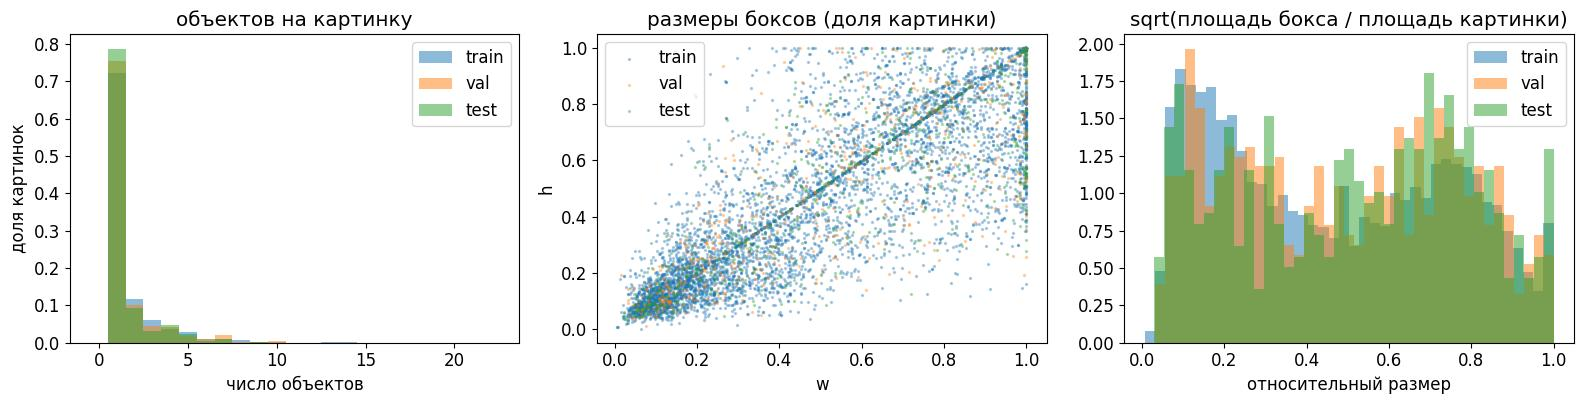

In [11]:
SMALL_OBJECT_AREA = 32 ** 2   # порог "мелкого" объекта из COCO, px^2


def split_stats(recs):
    objects_per_image = np.array([len(r['labels']) for r in recs])
    labels = np.concatenate([r['labels'] for r in recs])
    boxes = np.concatenate([r['boxes'] for r in recs])
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return dict(images=len(recs), objects=len(labels),
                **{f'obj_{name}': int((labels == k).sum()) for k, name in enumerate(CLASSES)},
                obj_per_img_mean=round(float(objects_per_image.mean()), 2), obj_per_img_max=int(objects_per_image.max()),
                empty_images=int((objects_per_image == 0).sum()), small_share=round(float((areas < SMALL_OBJECT_AREA).mean()), 3))


stats_table = {split: split_stats(recs) for split, recs in records.items()}
columns = list(next(iter(stats_table.values())))
print(f'{"split":<6}' + ''.join(f'{c:>17}' for c in columns))
for split, row in stats_table.items():
    print(f'{split:<6}' + ''.join(f'{row[c]:>17}' for c in columns))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for split, recs in records.items():
    counts = [len(r['labels']) for r in recs]
    axes[0].hist(counts, bins=np.arange(0, max(counts) + 2) - 0.5, alpha=0.5, density=True, label=split)
    boxes = np.concatenate([r['boxes'] / [r['width'], r['height'], r['width'], r['height']] for r in recs])
    axes[1].scatter(boxes[:, 2] - boxes[:, 0], boxes[:, 3] - boxes[:, 1], s=2, alpha=0.3, label=split)
    axes[2].hist(np.sqrt((boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])), bins=40, alpha=0.5, density=True, label=split)
axes[0].set(title='объектов на картинку', xlabel='число объектов', ylabel='доля картинок')
axes[1].set(title='размеры боксов (доля картинки)', xlabel='w', ylabel='h')
axes[2].set(title='sqrt(площадь бокса / площадь картинки)', xlabel='относительный размер')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

**Ответ:** Garbage Detection v8 с Roboflow Universe, CC BY 4.0, один класс `garbage` (кучи мусора, мешки, свалки на улице). 5777 картинок, растянутых Roboflow до 640x640, авторский сплит 4730/629/418. Но исходных фото всего 1904, у каждого в среднем 3 копии (повороты, кропы, мозаика), и у 452 фото копии лежат и в train, и в val/test. Поэтому пересобрал сплит по исходному фото (префикс имени до `.rf.`, seed 0, 60/20/20 по фото, в val/test одна копия на фото): 3394/381/381 картинок, 5846/630/572 объектов. Фото с типовыми именами вроде `img143` при этом могут склеиться в одну группу, но утечки это не дает.

Класс один, дисбаланса нет. В среднем 1.7 объекта на картинку, больше 70% картинок с одним объектом, максимум 22: плотные сцены редки. Мельче 32x32 px около 1% боксов, зато много боксов почти во весь кадр (полосы w=1 и h=1 на scatter). Главная проблема разметки - разная гранулярность: где-то вся куча одним боксом, где-то каждый мешок или бутылка отдельно. Обрезан по границе 1 бокс, вырожденных 0.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
YOLO_FLOAT_FORMAT = '.6f'


def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, нормировано в [0, 1]
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    centers_x = (boxes[:, 0] + boxes[:, 2]) / 2 / width
    centers_y = (boxes[:, 1] + boxes[:, 3]) / 2 / height
    widths = (boxes[:, 2] - boxes[:, 0]) / width
    heights = (boxes[:, 3] - boxes[:, 1]) / height
    rows = zip(np.asarray(labels).reshape(-1), centers_x, centers_y, widths, heights)
    return ''.join(f'{int(label)} {cx:{YOLO_FLOAT_FORMAT}} {cy:{YOLO_FLOAT_FORMAT}} {w:{YOLO_FLOAT_FORMAT}} {h:{YOLO_FLOAT_FORMAT}}\n'
                   for label, cx, cy, w, h in rows)


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    rows = [line.split() for line in text.splitlines() if line.strip()]
    if not rows:
        return np.zeros((0, 4), dtype=np.float32), np.zeros(0, dtype=np.int64)
    values = np.array(rows, dtype=np.float64)
    centers_x, centers_y = values[:, 1] * width, values[:, 2] * height
    half_widths, half_heights = values[:, 3] * width / 2, values[:, 4] * height / 2
    boxes = np.stack([centers_x - half_widths, centers_y - half_heights,
                      centers_x + half_widths, centers_y + half_heights], axis=1)
    return boxes.astype(np.float32), values[:, 0].astype(np.int64)

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    image_dir, label_dir = YOLO_ROOT / 'images' / split, YOLO_ROOT / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    for r in recs:
        source = Path(r['image'])
        shutil.copy(source, image_dir / source.name)
        (label_dir / f'{source.stem}.txt').write_text(to_yolo(r['boxes'], r['labels'], r['width'], r['height']))


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от другого прогона
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: D:/Learning/DeepLearning/hw2_students/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: garbage



туда-обратно через txt: 4156 картинок, макс. ошибка координат 0.0003 px


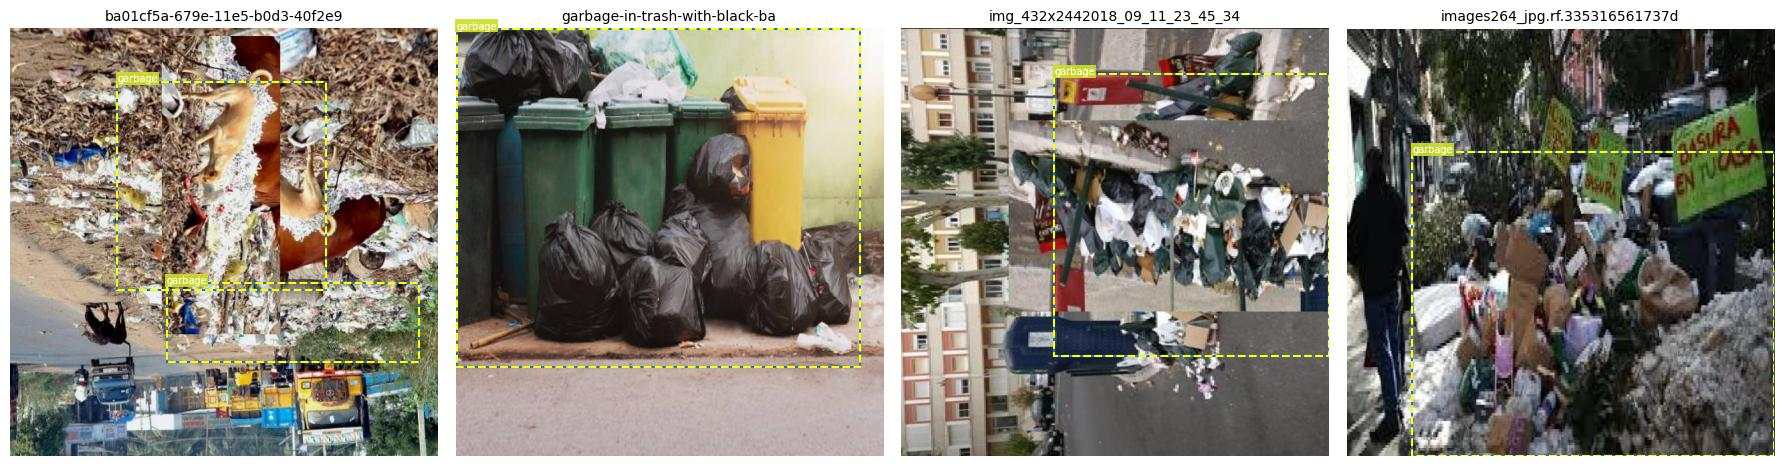

In [15]:
def read_back(record, split):
    label_path = YOLO_ROOT / 'labels' / split / f'{Path(record["image"]).stem}.txt'
    return from_yolo(label_path.read_text(), record['width'], record['height'])


# 1) туда-обратно через файлы на диске для всех экспортированных картинок
max_error, n_checked = 0.0, 0
for split, recs in splits.items():
    for r in recs:
        boxes, labels = read_back(r, split)
        assert (labels == r['labels']).all() and boxes.shape == r['boxes'].shape, r['image']
        max_error = max(max_error, float(np.abs(boxes - r['boxes']).max(initial=0)))
        n_checked += 1
print(f'туда-обратно через txt: {n_checked} картинок, макс. ошибка координат {max_error:.4f} px')

# 2) глазами: исходные боксы из COCO (пунктир) и прочитанные из txt (сплошные) должны совпасть
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
sample = np.random.default_rng(SEED).choice(len(records['val']), size=4, replace=False)
for ax, index in zip(axes, sample):
    r = records['val'][index]
    boxes, labels = read_back(r, 'val')
    draw_boxes(ax, Image.open(r['image']), boxes, labels, CLASSES, title=Path(r['image']).name[:30])
    draw_boxes(ax, None, r['boxes'], r['labels'], CLASSES, color='yellow', linestyle='--')
plt.tight_layout()
plt.show()

**Ответ:** Тест туда-обратно проверяет, что `to_yolo` и `from_yolo` взаимно обратны: нормировка, переход центр/размер и порядок колонок согласованы. На 4156 картинках максимальная ошибка 0.0003 px, это округление до 6 знаков. Он не ловит ошибки, одинаковые в обеих функциях (например, x и y перепутаны и там, и там), неправильный разбор исходника (COCO `xywh`, прочитанный как `xyxy`), неверный маппинг классов и разметку, записанную не к той картинке. Такие ошибки видны только на картинке: боксы сдвинуты или раздуты, отражены по оси, не повернуты вместе с EXIF-ориентацией или вообще от другого кадра. На рисунке выше желтый пунктир (COCO) и сплошные боксы (из txt) совпадают.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

coco_map50 = 0.0 (нет совпадающего класса); class-agnostic mAP50 = 0.013
картинок с хотя бы одним боксом conf>=0.25: 174/381
топ COCO-классов на test [('person', 173), ('car', 137), ('truck', 43), ('bird', 15), ('umbrella', 14), ('motorcycle', 9), ('backpack', 8), ('boat', 8), ('suitcase', 6), ('handbag', 6)]


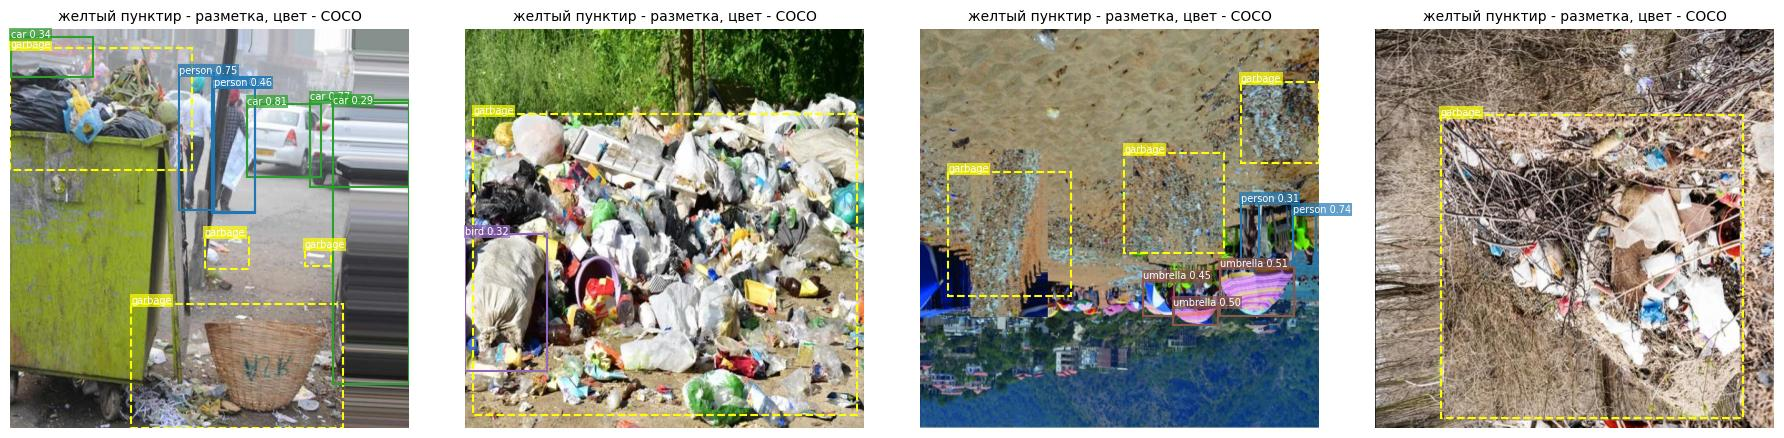

In [16]:
DISPLAY_CONF = 0.25   # порог по умолчанию у model.predict, для показа и подсчета классов

coco_preds = predict_records(model_coco, records[FINAL_SPLIT])
coco_map50 = 0.0   # класса garbage в COCO нет -> ни одно предсказание не может совпасть по классу, AP = 0 по определению

# для понимания: считаем любой COCO-бокс "мусором" (class-agnostic) - насколько хорошо модель хотя бы локализует кучи
agnostic_preds = [dict(p, labels=np.zeros_like(p['labels'])) for p in coco_preds]
coco_agnostic_map50, _ = evaluate_map50(agnostic_preds, records[FINAL_SPLIT], len(CLASSES))
coco_class_counts = Counter(model_coco.names[int(label)] for p in coco_preds
                            for label, score in zip(p['labels'], p['scores']) if score >= DISPLAY_CONF)
n_with_preds = sum((p['scores'] >= DISPLAY_CONF).any() for p in coco_preds)
print(f'coco_map50 = {coco_map50} (нет совпадающего класса); class-agnostic mAP50 = {coco_agnostic_map50:.3f}')
print(f'картинок с хотя бы одним боксом conf>={DISPLAY_CONF}: {n_with_preds}/{len(coco_preds)}')
print('топ COCO-классов на', FINAL_SPLIT, coco_class_counts.most_common(10))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, index in zip(axes, np.random.default_rng(SEED + 1).choice(len(coco_preds), size=4, replace=False)):
    p, r = coco_preds[index], records[FINAL_SPLIT][index]
    keep = p['scores'] >= DISPLAY_CONF
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, color='yellow', linestyle='--')
    draw_boxes(ax, None, p['boxes'][keep], p['labels'][keep], model_coco.names, scores=p['scores'][keep],
               title='желтый пунктир - разметка, цвет - COCO')
plt.tight_layout()
plt.show()

In [17]:
def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей:
    # одни и те же "типичные" боксы из train (центры k-means по нормированным xyxy), score - доля train-боксов в кластере
    with Image.open(image_path) as image:
        width, height = image.size
    scale = np.array([width, height, width, height])
    return dict(boxes=(PRIOR_BOXES * scale).astype(np.float32), scores=PRIOR_SCORES.copy(), labels=PRIOR_LABELS.copy())

In [18]:
from scipy.cluster.vq import kmeans2

HEURISTIC_K_GRID = (1, 2, 4, 8, 16, 32, 64)
N_HEURISTIC_FIT_EVAL = 500   # на скольких train-картинках выбираем k


def normalized_boxes(recs, class_index):
    return np.concatenate([r['boxes'][r['labels'] == class_index] / [r['width'], r['height'], r['width'], r['height']]
                           for r in recs])


def fit_priors(recs, k):
    # k-means по каждому классу отдельно; score = доля боксов класса в кластере (частые формы - выше)
    boxes, scores, labels = [], [], []
    for class_index in range(len(CLASSES)):
        points = normalized_boxes(recs, class_index)
        centers, assignment = kmeans2(points, min(k, len(points)), seed=SEED, minit='++')
        counts = np.bincount(assignment, minlength=len(centers))
        keep = counts > 0
        boxes.append(centers[keep])
        scores.append(counts[keep] / counts.sum())
        labels.append(np.full(keep.sum(), class_index))
    return np.concatenate(boxes), np.concatenate(scores), np.concatenate(labels).astype(np.int64)


fit_eval_recs = [records['train'][i] for i in np.random.default_rng(SEED).permutation(len(records['train']))[:N_HEURISTIC_FIT_EVAL]]
heuristic_search = {}
for k in HEURISTIC_K_GRID:
    PRIOR_BOXES, PRIOR_SCORES, PRIOR_LABELS = fit_priors(records['train'], k)
    heuristic_search[k], _ = evaluate_map50([heuristic_detect(r['image']) for r in fit_eval_recs], fit_eval_recs, len(CLASSES))
HEURISTIC_K = max(heuristic_search, key=heuristic_search.get)
PRIOR_BOXES, PRIOR_SCORES, PRIOR_LABELS = fit_priors(records['train'], HEURISTIC_K)
print('mAP50 на train по k:', {k: round(v, 3) for k, v in heuristic_search.items()}, '-> k =', HEURISTIC_K)

mAP50 на train по k: {1: 0.001, 2: 0.027, 4: 0.177, 8: 0.183, 16: 0.188, 32: 0.175, 64: 0.167} -> k = 16


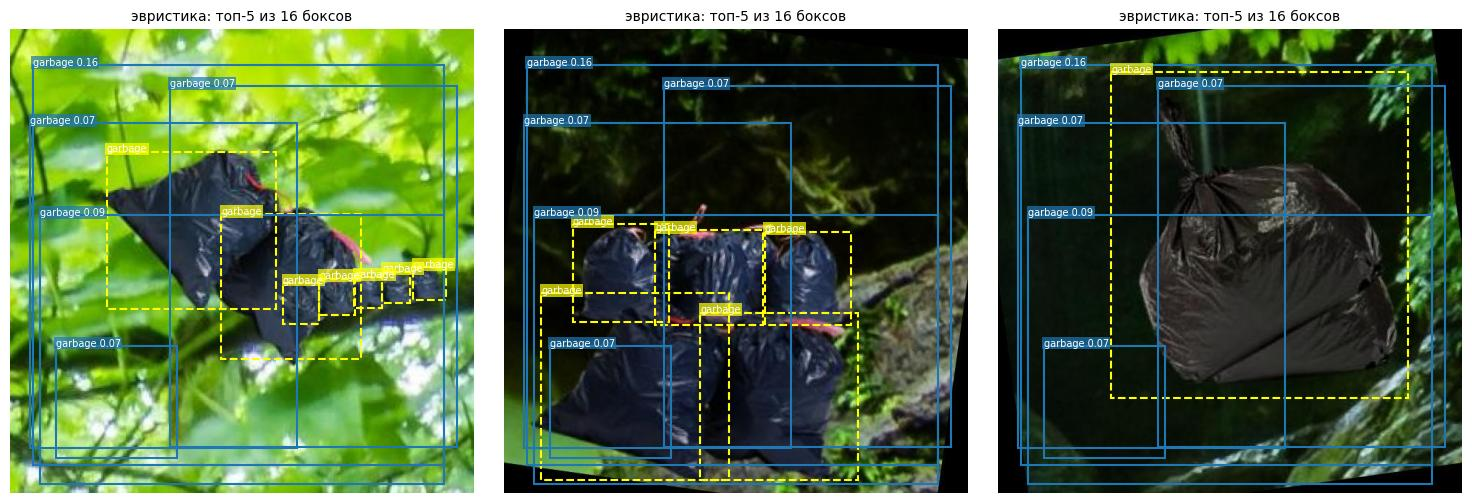

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.2611675633779723,
 'heuristic_ap50_per_class': {'garbage': 0.2611675633779723},
 'coco_agnostic_map50': 0.01289159624245627}

In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
BASELINE['coco_agnostic_map50'] = coco_agnostic_map50   # доп. число, см. выше
N_SHOWN_PRIORS = 5
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, r, p in zip(axes, records[FINAL_SPLIT][:3], heuristic_preds[:3]):
    top = np.argsort(-p['scores'])[:N_SHOWN_PRIORS]
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, color='yellow', linestyle='--')
    draw_boxes(ax, None, p['boxes'][top], p['labels'][top], CLASSES, scores=p['scores'][top],
               title=f'эвристика: топ-{N_SHOWN_PRIORS} из {len(p["scores"])} боксов')
plt.tight_layout()
plt.show()
BASELINE

**Ответ:** Класса garbage в COCO нет, поэтому mAP COCO-модели равен 0 по определению. На test она находит то, что рядом с мусором: person 173, car 137, truck 43, дальше bird, umbrella и т.п. Даже если считать мусором любой ее бокс, mAP50 всего 0.013: модель выделяет отдельные предметы, а в разметке бокс обычно на всю кучу, и IoU не дотягивает до 0.5.

Эвристика из 16 типичных боксов train (k-means по нормированным координатам, k выбран по train) дает на test mAP50 0.261. Она работает, потому что объекты крупные и часто стоят по центру или занимают весь кадр, и какой-то из шаблонов пересекается с ними с IoU ≥ 0.5. На картинках с несколькими мелкими объектами она не работает: они не похожи ни на один шаблон. Класс один, поэтому разбивки по классам нет.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
TRAIN_ARGS = dict(
    epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
    optimizer='AdamW', lr0=1e-3, cos_lr=True, warmup_epochs=3,
    patience=15,            # ранняя остановка, если mAP50-95 на val не растет 15 эпох
    fliplr=0.5, flipud=0.0,  # кучи мусора снимают с земли: верх/низ осмысленны
    degrees=0.0, mosaic=1.0, close_mosaic=10,   # повороты на 90° уже "запечены" в датасет Roboflow
    cache='disk',           # декодированные .npy рядом с картинками: на Windows с workers=0 узкое место - чтение jpeg;
                            # 'ram' не годится - кэш каждого обучения остается в памяти ядра и к бонусам RAM кончается
    seed=SEED, plots=True,
)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

train: Caching images (3.9GB Disk): 100% ━━━━━━━━━━━━ 3394/3394 2.1Kit/s 1.6s0.0s
val: Caching images (0.4GB Disk): 100% ━━━━━━━━━━━━ 381/381 2.0Kit/s 0.2s<0.3s
обучение: 3786 s на NVIDIA GeForce RTX 2060, каталог D:\Learning\DeepLearning\hw2_students\runs_hw2\finetune


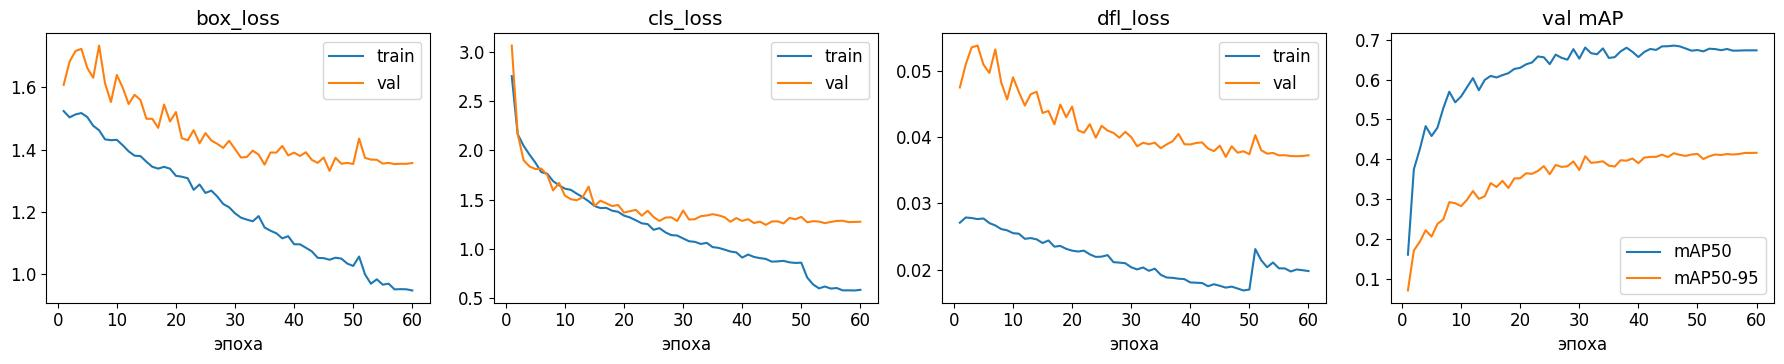

эпох пройдено: 60 из 60, лучшая по mAP50-95: 60; время 63.1 мин на NVIDIA GeForce RTX 2060


In [22]:
results = read_results(run_dir)
epochs_axis = results['epoch']
loss_names = sorted(k.split('/', 1)[1] for k in results if k.startswith('train/') and 'loss' in k)
fig, axes = plt.subplots(1, len(loss_names) + 1, figsize=(4.5 * (len(loss_names) + 1), 3.8))
for ax, name in zip(axes, loss_names):
    ax.plot(epochs_axis, results[f'train/{name}'], label='train')
    if f'val/{name}' in results:
        ax.plot(epochs_axis, results[f'val/{name}'], label='val')
    ax.set(title=name, xlabel='эпоха')
    ax.legend()
axes[-1].plot(epochs_axis, results['metrics/mAP50(B)'], label='mAP50')
axes[-1].plot(epochs_axis, results['metrics/mAP50-95(B)'], label='mAP50-95')
axes[-1].set(title='val mAP', xlabel='эпоха')
axes[-1].legend()
plt.tight_layout()
plt.show()
best_epoch = int(epochs_axis[np.argmax(results['metrics/mAP50-95(B)'])])
print(f'эпох пройдено: {len(epochs_axis)} из {EPOCHS}, лучшая по mAP50-95: {best_epoch}; '
      f'время {RUN_TIMES["train"] / 60:.1f} мин на {DEVICE_NAME}')

**Ответ:** 60 эпох при 640 укладываются примерно в час (~63 с на эпоху), 640 - родное разрешение датасета, batch 16 занимает до 2.9 из 6 ГБ. AdamW, lr 1e-3, cosine и 3 эпохи warmup - обычный рецепт дообучения на нескольких тысячах картинок; patience 15 (не сработал). fliplr да, flipud нет: снимки с земли, верх и низ осмысленны. degrees 0, потому что повороты уже есть в датасете. Мозаика отключается на последних 10 эпохах.

Явного переобучения нет: train loss падает все 60 эпох, val loss к 35-40 эпохе выходит на плато и не растет. Зазор растет, модель начинает подгоняться под train, но val mAP не падает. Скачок train dfl_loss на 51-й эпохе - отключение мозаики. Эпох хватило: с 44-й эпохи val mAP50-95 колеблется в 0.40-0.416 (лучшая - 60-я, 0.416).

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

split    mAP50  mAP50-95      P      R
val      0.673     0.416  0.795  0.622
  garbage    AP50 0.673  AP50-95 0.416  P 0.795  R 0.622
test     0.721     0.444  0.851  0.652
  garbage    AP50 0.721  AP50-95 0.444  P 0.851  R 0.652
mAP50 на test: ultralytics 0.7208, evaluate_map50 0.7039


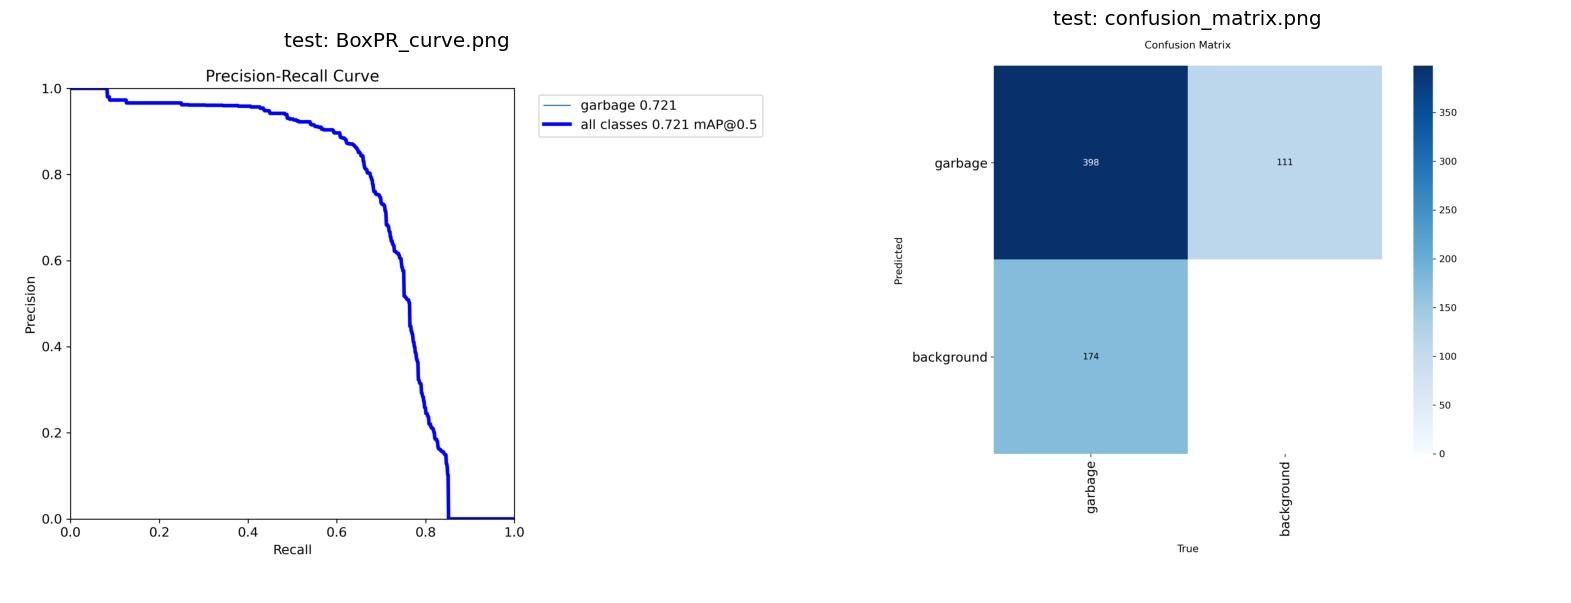

In [24]:
def summarize_metrics(result):
    box = result.box
    per_class = {CLASSES[int(c)]: dict(ap50=float(box.ap50[k]), ap50_95=float(box.ap[k]),
                                       precision=float(box.p[k]), recall=float(box.r[k]))
                 for k, c in enumerate(box.ap_class_index)}
    return dict(map50=float(box.map50), map50_95=float(box.map), precision=float(box.mp), recall=float(box.mr),
                per_class=per_class)


val_result = val_metrics(best, 'val', 'final_val')
final_result = val_metrics(best, FINAL_SPLIT, f'final_{FINAL_SPLIT}')
FINAL_VAL = summarize_metrics(val_result)
FINAL = summarize_metrics(final_result)
FINAL['split'] = FINAL_SPLIT

print(f'{"split":<6} {"mAP50":>7} {"mAP50-95":>9} {"P":>6} {"R":>6}')
for split, m in (('val', FINAL_VAL), (FINAL_SPLIT, FINAL)):
    print(f'{split:<6} {m["map50"]:>7.3f} {m["map50_95"]:>9.3f} {m["precision"]:>6.3f} {m["recall"]:>6.3f}')
    for name, c in m['per_class'].items():
        print(f'  {name:<10} AP50 {c["ap50"]:.3f}  AP50-95 {c["ap50_95"]:.3f}  P {c["precision"]:.3f}  R {c["recall"]:.3f}')

own_preds = predict_records(best, records[FINAL_SPLIT])
FINAL['map50_own'], _ = evaluate_map50(own_preds, records[FINAL_SPLIT], len(CLASSES))
print(f'mAP50 на {FINAL_SPLIT}: ultralytics {FINAL["map50"]:.4f}, evaluate_map50 {FINAL["map50_own"]:.4f}')

plot_dir = Path(final_result.save_dir)
plot_files = [next(plot_dir.glob(pattern)) for pattern in ('*PR_curve.png', 'confusion_matrix.png')]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, path in zip(axes, plot_files):
    ax.imshow(plt.imread(path))
    ax.set_axis_off()
    ax.set_title(f'{FINAL_SPLIT}: {path.name}')
plt.tight_layout()
plt.show()

In [25]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.7208,
 'map50_95': 0.4442,
 'precision': 0.8508,
 'recall': 0.6521,
 'split': 'test',
 'map50_own': 0.7039}

**Ответ:** На test mAP50 0.721, mAP50-95 0.444, P 0.851, R 0.652 (на val 0.673 / 0.416, разница - скорее шум выборок по 381 картинке). Класс один, сравнивать классы не с чем; по 5.1 хуже всего мелкий разбросанный мусор и отдельные мешки внутри большой кучи. В confusion matrix 398 объектов найдено, 174 в строке background (пропуски), 111 в столбце background (лишние боксы на фоне), так что главная проблема - recall. mAP50-95 намного ниже mAP50, потому что граница кучи размыта и размечена непоследовательно: при IoU 0.75-0.95 бокс редко совпадает с разметкой. Своя `evaluate_map50` дала 0.704 против 0.721: ultralytics интерполирует PR-кривую по 101 точке (у меня all-point) и сопоставляет предсказания с gt по убыванию IoU, а не жадно по score.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [26]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустой вход -> пустая форма (n, m)
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float64).reshape(-1, 4)
    top_left = np.maximum(a[:, None, :2], b[None, :, :2])
    bottom_right = np.minimum(a[:, None, 2:], b[None, :, 2:])
    intersection = np.clip(bottom_right - top_left, 0, None).prod(axis=2)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    union = area_a[:, None] + area_b[None, :] - intersection
    return intersection / np.maximum(union, np.finfo(np.float64).tiny)


def best_gt(ious, candidates):
    # индекс gt с максимальным IoU среди candidates (bool-маска) или None
    if not candidates.any():
        return None
    return int(np.argmax(np.where(candidates, ious, -1.0)))


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    pred_labels, gt_labels = np.asarray(pred['labels']).reshape(-1), np.asarray(gt['labels']).reshape(-1)
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    is_found = np.zeros(len(gt_labels), dtype=bool)
    is_explained = np.zeros(len(gt_labels), dtype=bool)   # к gt привязана ошибка класса или локализации
    categories = [None] * len(pred_labels)
    for i in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        same_class = gt_labels == pred_labels[i]
        rules = (('tp', same_class & ~is_found & (ious[i] >= iou_hit)),
                 ('class', ~same_class & (ious[i] >= iou_hit)),
                 ('localization', same_class & ~is_found & (ious[i] >= iou_loc) & (ious[i] < iou_hit)))
        categories[i] = 'background'
        for category, candidates in rules:
            j = best_gt(ious[i], candidates)
            if j is None:
                continue
            categories[i] = category
            if category == 'tp':
                is_found[j] = True
            else:
                is_explained[j] = True
            break
    missed = [j for j in range(len(gt_labels)) if not is_found[j] and not is_explained[j]]
    return categories, missed

In [27]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


val, conf >= 0.25: 562 предсказаний, 630 объектов
  tp              406  (72.2% предсказаний)
  class             0  (0.0% предсказаний)
  localization     79  (14.1% предсказаний)
  background       77  (13.7% предсказаний)
  missed          170  (27.0% объектов)
  класс garbage: {'tp': 406, 'class': 0, 'localization': 79, 'background': 77, 'missed': 170}


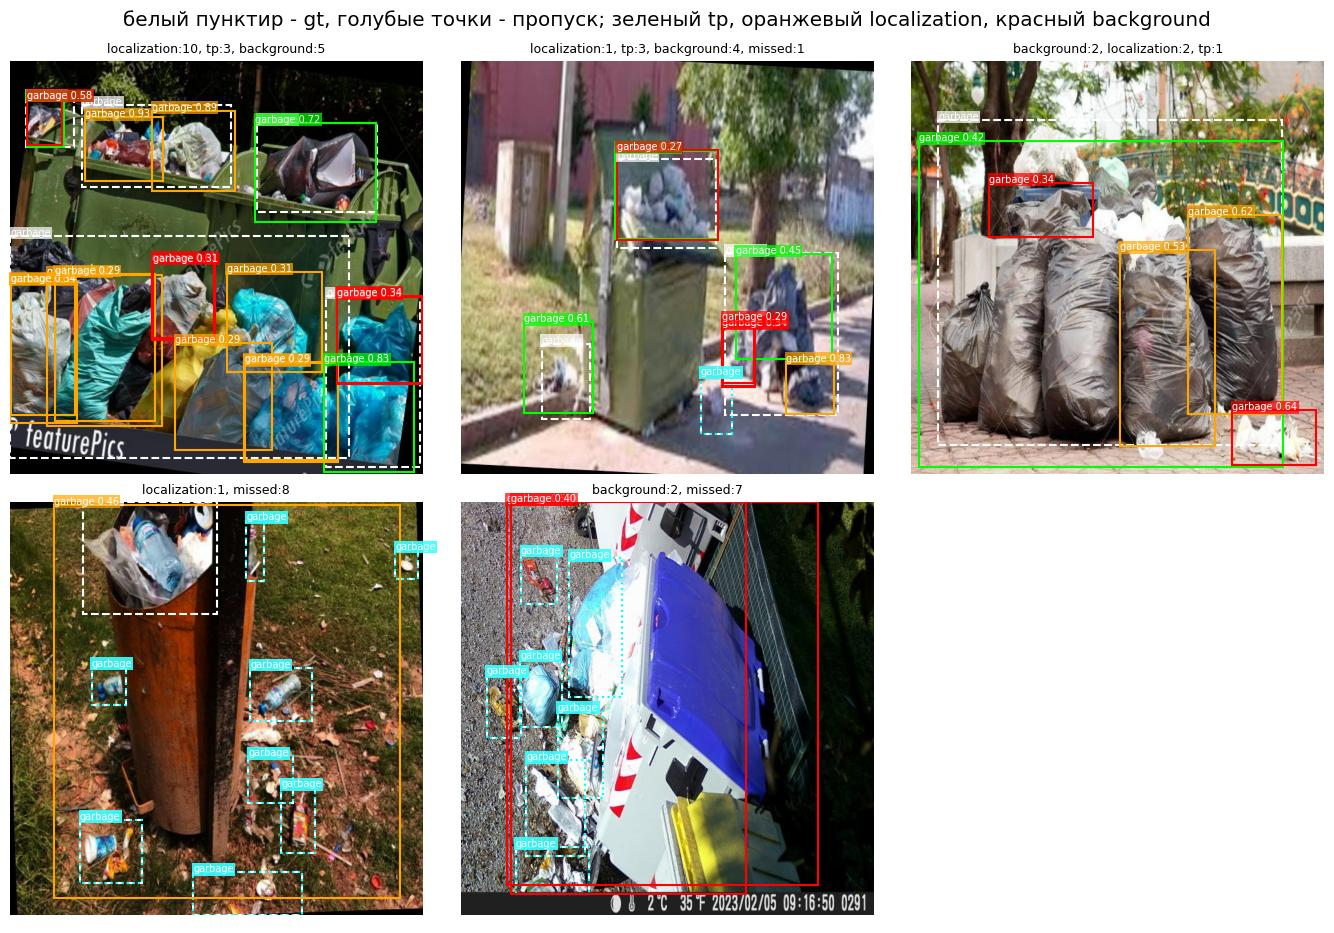

In [28]:
CATEGORY_COLORS = {'tp': 'lime', 'class': 'magenta', 'localization': 'orange', 'background': 'red'}
N_EXAMPLES_PER_TYPE = 2

val_preds = predict_records(best, records['val'], conf=CONF_ERRORS)
per_image = [categorize_predictions(p, g) for p, g in zip(val_preds, records['val'])]
error_counts, by_class = Counter(), {name: Counter() for name in CLASSES}
for (categories, missed), p, g in zip(per_image, val_preds, records['val']):
    for category, label in zip(categories, p['labels']):
        error_counts[category] += 1
        by_class[CLASSES[label]][category] += 1
    for j in missed:
        error_counts['missed'] += 1
        by_class[CLASSES[g['labels'][j]]]['missed'] += 1
ERRORS = {t: int(error_counts[t]) for t in ERROR_TYPES}

n_predictions = sum(ERRORS[t] for t in ERROR_TYPES if t != 'missed')
n_gt = sum(len(g['labels']) for g in records['val'])
print(f'val, conf >= {CONF_ERRORS}: {n_predictions} предсказаний, {n_gt} объектов')
for t in ERROR_TYPES:
    share = ERRORS[t] / n_gt if t == 'missed' else ERRORS[t] / max(n_predictions, 1)
    print(f'  {t:<13} {ERRORS[t]:>5}  ({share:.1%} {"объектов" if t == "missed" else "предсказаний"})')
for name, counter in by_class.items():
    print(f'  класс {name}:', {t: counter[t] for t in ERROR_TYPES})


def draw_error_example(ax, index):
    r, p = records['val'][index], val_preds[index]
    categories, missed = per_image[index]
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, color='white', linestyle='--')
    draw_boxes(ax, None, r['boxes'][missed], r['labels'][missed], CLASSES, color='cyan', linestyle=':')
    for category, color in CATEGORY_COLORS.items():
        keep = np.array([c == category for c in categories], dtype=bool)
        draw_boxes(ax, None, p['boxes'][keep], p['labels'][keep], CLASSES, scores=p['scores'][keep], color=color)
    summary = Counter(categories) + Counter(missed=len(missed))
    ax.set_title(', '.join(f'{k}:{v}' for k, v in summary.items()), fontsize=9)


def count_in_image(index, error_type):
    categories, missed = per_image[index]
    return len(missed) if error_type == 'missed' else categories.count(error_type)


examples = []
for error_type in ('background', 'localization', 'missed', 'class'):
    ranked = sorted(range(len(per_image)), key=lambda i: -count_in_image(i, error_type))
    examples += [i for i in ranked[:N_EXAMPLES_PER_TYPE] if count_in_image(i, error_type) > 0 and i not in examples]
fig, axes = plt.subplots(2, math.ceil(len(examples) / 2), figsize=(4.5 * math.ceil(len(examples) / 2), 9.5), squeeze=False)
for ax, index in zip(axes.flat, examples):
    draw_error_example(ax, index)
for ax in axes.flat[len(examples):]:
    ax.set_axis_off()
fig.suptitle('белый пунктир - gt, голубые точки - пропуск; зеленый tp, оранжевый localization, красный background')
plt.tight_layout()
plt.show()

**Ответ:** Главная категория - пропуски: 170, это 27% объектов val. Дальше localization 79 и background 77 (по 14% предсказаний), ошибок класса 0, потому что класс один. По примерам это в основном неоднозначность разметки, а не слепота модели. Где gt - одна большая куча, модель выделяет отдельные мешки, и они уходят в localization и background. Где разметчик обвел каждую бутылку на траве, модель дает один большой бокс или ничего, отсюда 7-8 пропусков на картинку. Чтобы уменьшить пропуски, сначала нужно единое правило разметки (куча целиком или каждый предмет, можно два класса `pile` / `item`) и переразметка, а для мелкого разбросанного мусора - больше imgsz или тайлинг.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [29]:
ABLATION_IMGSZ = IMGSZ // 2


def val_at(model, imgsz, name, split='val', **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=imgsz, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, plots=False, **kw)


_, RUN_TIMES['ablation'], ablation_dir = train_yolo('ablation_imgsz', **{**TRAIN_ARGS, 'imgsz': ABLATION_IMGSZ})
best_small = YOLO(ablation_dir / 'weights' / 'best.pt')
small_val = summarize_metrics(val_at(best_small, ABLATION_IMGSZ, 'ablation_val'))
ABLATION = dict(
    param='imgsz', values=[IMGSZ, ABLATION_IMGSZ],
    map50=[FINAL_VAL['map50'], small_val['map50']], map50_95=[FINAL_VAL['map50_95'], small_val['map50_95']],
    train_time_sec=[RUN_TIMES['train'], RUN_TIMES['ablation']],
    latency_ms=[measure_latency_ms(best, IMGSZ), measure_latency_ms(best_small, ABLATION_IMGSZ)],
    epochs_run=[len(read_results(run_dir)['epoch']), len(read_results(ablation_dir)['epoch'])],
)
print(f'{"imgsz":>6} {"mAP50":>7} {"mAP50-95":>9} {"train, мин":>11} {"эпох":>5} {"latency, мс":>12}')
for k in range(2):
    print(f'{ABLATION["values"][k]:>6} {ABLATION["map50"][k]:>7.3f} {ABLATION["map50_95"][k]:>9.3f} '
          f'{ABLATION["train_time_sec"][k] / 60:>11.1f} {ABLATION["epochs_run"][k]:>5} {ABLATION["latency_ms"][k]:>12.1f}')

train: Caching images (3.9GB Disk): 100% ━━━━━━━━━━━━ 3394/3394 51.9Kit/s 0.1s
val: Caching images (0.4GB Disk): 100% ━━━━━━━━━━━━ 381/381 71.1Kit/s 0.0s
 imgsz   mAP50  mAP50-95  train, мин  эпох  latency, мс
   640   0.673     0.416        63.1    60          8.5
   320   0.656     0.398        32.8    59          7.1


**Ответ:** При 320 вместо 640 mAP50 на val 0.656 против 0.673, mAP50-95 0.398 против 0.416, а обучение 32.8 мин против 63.1 (59 эпох, ранний останов). Задержка на GPU почти та же, 7.1 против 8.5 мс: у nano-модели при batch 1 время уходит в основном на пре- и постобработку и запуск ядер; FLOPs меньше в 4 раза, так что на CPU выигрыш был бы заметнее. Просело мало, потому что объекты крупные (мельче 32 px около 1%), и разница ~0.02 может быть в пределах шума одного сида. Для быстрых итераций или слабого железа 320 того стоит, для финальной модели оставил бы 640.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** Дообученная yolo26n дала на test mAP50 0.721 / mAP50-95 0.444 против 0.261 у эвристики из 16 шаблонных боксов и 0 у COCO-модели. Сработала пересборка сплита по исходным фото (иначе копии одного фото попали бы и в train, и в test), обычный рецепт AdamW + mosaic обучился за час без переобучения, а imgsz 320 почти не хуже 640 (0.656 против 0.673 на val) при вдвое более быстром обучении. Не сработали RT-DETR-l на 6 ГБ при 320 и 10 эпохах (0.533 против 0.656 mAP50) и FP16 на GPU, который не ускорил nano-модель. Ограничения: val и test по 381 картинке, так что 0.02 mAP - уже шум, один seed, один класс. Потолок, видимо, задает непоследовательная разметка (куча целиком против отдельных предметов), отсюда и низкий mAP50-95. Дальше: единое правило разметки (или два класса) и переразметка, несколько сидов, JPEG- и шум-аугментации (см. 6.3), тайлинг для мелкого мусора.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [31]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** не делал.

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [32]:
if '6.2' in BONUS_TASKS:
    from ultralytics import RTDETR
    import warnings
    # torch на каждой эпохе предупреждает, что backward grid_sample недетерминирован (ultralytics включает deterministic)
    warnings.filterwarnings('ignore', message='grid_sampler_2d_backward_cuda')
    # rtdetr-l (33M) на RTX 2060 6 ГБ: при 640 даже batch 2 упирается в память (Windows выгружает ее в RAM, ~1.6 с/итерация).
    # Поэтому 320 - сравниваем с YOLO из абляции на том же 320 (объекты крупные, 320 почти не хуже 640)
    RTDETR_IMGSZ = ABLATION_IMGSZ
    RTDETR_EPOCHS = 2 if FAST_MODE else 10
    RTDETR_BATCH = 4

    rtdetr = RTDETR('rtdetr-l.pt')
    rtdetr_params = sum(p.numel() for p in rtdetr.model.parameters())
    start = time.perf_counter()
    rtdetr.train(data=str(DATA_YAML), epochs=RTDETR_EPOCHS, imgsz=RTDETR_IMGSZ, batch=RTDETR_BATCH, device=DEVICE,
                 workers=WORKERS, project=str(RUNS.resolve()), name='rtdetr', exist_ok=True, verbose=False,
                 optimizer='AdamW', lr0=1e-4, cos_lr=True, fliplr=0.5, flipud=0.0,
                 cache='disk', seed=SEED, plots=False)
    RUN_TIMES['rtdetr_train'] = time.perf_counter() - start
    rtdetr_best = RTDETR(Path(rtdetr.trainer.save_dir) / 'weights' / 'best.pt')
    rtdetr_val = summarize_metrics(val_at(rtdetr_best, RTDETR_IMGSZ, 'rtdetr_val'))
    RTDETR_COMPARISON = {
        f'yolo26n@{ABLATION_IMGSZ}': dict(map50=small_val['map50'], map50_95=small_val['map50_95'],
                                          params=sum(blocks.values()), epochs=ABLATION['epochs_run'][1],
                                          train_min=RUN_TIMES['ablation'] / 60, latency_ms=ABLATION['latency_ms'][1]),
        f'rtdetr-l@{RTDETR_IMGSZ}': dict(map50=rtdetr_val['map50'], map50_95=rtdetr_val['map50_95'], params=rtdetr_params,
                                          epochs=RTDETR_EPOCHS, train_min=RUN_TIMES['rtdetr_train'] / 60,
                                          latency_ms=measure_latency_ms(rtdetr_best, RTDETR_IMGSZ)),
    }
    print(f'{"":<13} {"mAP50":>7} {"mAP50-95":>9} {"params, M":>10} {"эпох":>5} {"train, мин":>11} {"latency, мс":>12}')
    for name, m in RTDETR_COMPARISON.items():
        print(f'{name:<13} {m["map50"]:>7.3f} {m["map50_95"]:>9.3f} {m["params"] / 1e6:>10.1f} {m["epochs"]:>5} '
              f'{m["train_min"]:>11.1f} {m["latency_ms"]:>12.1f}')

train: Caching images (3.9GB Disk): 100% ━━━━━━━━━━━━ 3394/3394 71.4Kit/s 0.0s
val: Caching images (0.4GB Disk): 100% ━━━━━━━━━━━━ 381/381 64.4Kit/s 0.0s
                mAP50  mAP50-95  params, M  эпох  train, мин  latency, мс
yolo26n@320     0.656     0.398        2.6    59        32.8          7.1
rtdetr-l@320    0.533     0.292       33.0    10        32.7         17.4


**Ответ:** При 320 на val RT-DETR-l за 10 эпох дал mAP50 0.533 / mAP50-95 0.292 против 0.656 / 0.398 у YOLO26n, при этом у него в 12.7 раза больше параметров (33.0M против 2.6M) и задержка 17.4 против 7.1 мс. За те же ~32 мин обучения он прошел 10 эпох против 59, так что выиграть ничего не удалось. Сравнение нечестное: RT-DETR недообучен, mAP50 к концу еще рос (0.485 на 6-й эпохе, 0.534 на 10-й), а трансформерным детекторам нужно больше эпох и памяти. Брал бы его при мощной видеокарте и длинном обучении, когда точность на сложных сценах важнее задержки, а на слабом железе и небольшом датасете - YOLO.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

clean  map50 0.673  map50_95 0.416
dark   map50 0.657  map50_95 0.401  precision 0.794  recall 0.567
noise  map50 0.423  map50_95 0.222  precision 0.683  recall 0.425
jpeg   map50 0.240  map50_95 0.102  precision 0.396  recall 0.281


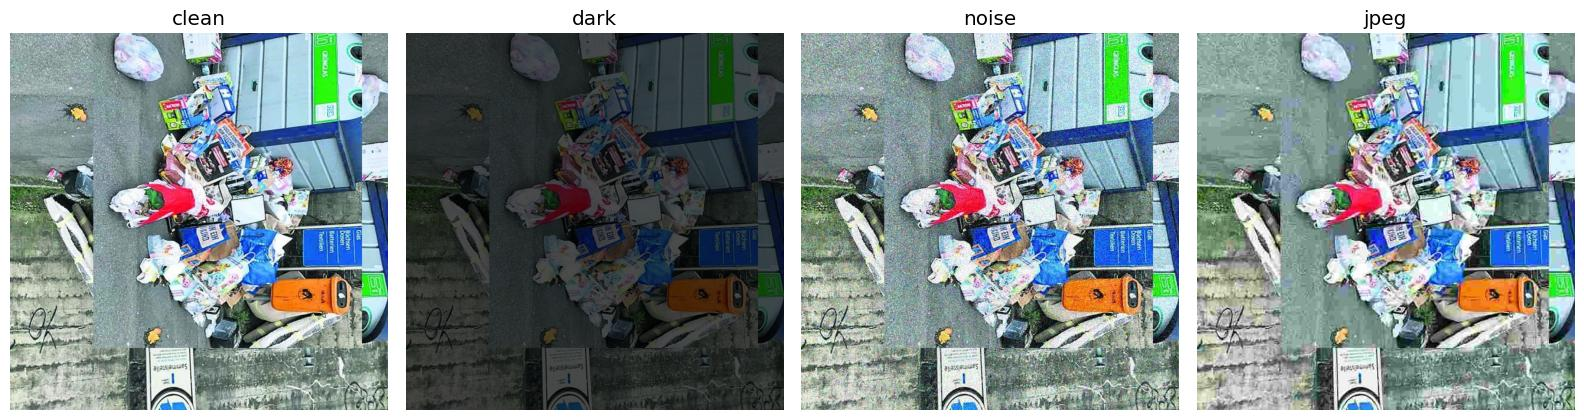

In [33]:
if '6.3' in BONUS_TASKS:
    DARKEN_FACTOR = 0.3
    NOISE_SIGMA = 30
    JPEG_QUALITY = 8
    noise_rng = np.random.default_rng(SEED)

    def darken(image):
        return Image.fromarray((np.asarray(image, dtype=np.float32) * DARKEN_FACTOR).astype(np.uint8))

    def add_noise(image):
        noisy = np.asarray(image, dtype=np.float32) + noise_rng.normal(0, NOISE_SIGMA, np.asarray(image).shape)
        return Image.fromarray(np.clip(noisy, 0, 255).astype(np.uint8))

    def jpeg_compress(image):
        buffer = io.BytesIO()
        image.save(buffer, format='JPEG', quality=JPEG_QUALITY)
        return Image.open(buffer).convert('RGB')

    DISTORTIONS = dict(dark=darken, noise=add_noise, jpeg=jpeg_compress)

    def export_distorted_val(name, distort):
        # копия val с искаженными картинками и той же разметкой + свой yaml, где val указывает на нее
        split = f'val_{name}'
        (YOLO_ROOT / 'images' / split).mkdir(parents=True, exist_ok=True)
        shutil.copytree(YOLO_ROOT / 'labels' / 'val', YOLO_ROOT / 'labels' / split, dirs_exist_ok=True)
        for r in records['val']:
            distort(Image.open(r['image']).convert('RGB')).save(YOLO_ROOT / 'images' / split / Path(r['image']).name, quality=95)
        yaml_path = YOLO_ROOT / f'data_{split}.yaml'
        yaml_path.write_text(DATA_YAML.read_text().replace('val: images/val\n', f'val: images/{split}\n'))
        return yaml_path

    SHIFT = {'clean': dict(map50=FINAL_VAL['map50'], map50_95=FINAL_VAL['map50_95'])}
    for name, distort in DISTORTIONS.items():
        yaml_path = export_distorted_val(name, distort)
        result = best.val(data=str(yaml_path), split='val', imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                          project=str(RUNS.resolve()), name=f'shift_{name}', exist_ok=True, verbose=False, plots=False)
        SHIFT[name] = {k: v for k, v in summarize_metrics(result).items() if k in ('map50', 'map50_95', 'precision', 'recall')}
    for name, m in SHIFT.items():
        print(f'{name:<6}', '  '.join(f'{k} {v:.3f}' for k, v in m.items()))

    example = records['val'][0]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
    clean_image = Image.open(example['image']).convert('RGB')
    for ax, (name, image) in zip(axes, [('clean', clean_image)] + [(n, f(clean_image)) for n, f in DISTORTIONS.items()]):
        ax.imshow(image)
        ax.set_title(name)
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

**Ответ:** Сильнее всего бьет JPEG quality 8: mAP50 на val 0.673 → 0.240, mAP50-95 0.416 → 0.102. Шум σ=30 дает 0.423, затемнение в 0.3 раза почти не влияет (0.657): ultralytics при обучении и так меняет яркость в 0.6-1.4 раза (`hsv_v=0.4`), а форма и текстура в темноте сохраняются. JPEG-блоки и шум как раз разрушают мелкую текстуру, по которой, видимо, и узнается мусор. Класс один, разбивки по классам нет. Помогли бы ImageCompression с низким quality, GaussNoise и Blur: их можно передать в `train(augmentations=[...])` списком albumentations-трансформов, в стандартном наборе ultralytics сжатия нет (у ImageCompression p=0).

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [34]:
if '6.4' in BONUS_TASKS:
    for package in ('onnx', 'onnxruntime', 'onnxslim'):
        if importlib.util.find_spec(package) is None:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', package], check=True)
    # при видимой CUDA ultralytics сам ставит onnxruntime-gpu через pip: это виснет и конфликтует с onnxruntime.
    # Без автоустановки он просто возьмет CPUExecutionProvider
    from ultralytics.utils import checks
    checks.AUTOINSTALL = False
    onnx_path = best.export(format='onnx', imgsz=IMGSZ, verbose=False)   # статический батч 1
    onnx_model = YOLO(onnx_path, task='detect')
    best_path = run_dir / 'weights' / 'best.pt'
    # у каждого варианта своя копия модели: val(half=True) переводит веса в fp16 прямо на месте
    variants = {'torch fp32 cpu': (YOLO(best_path), 'cpu', {}), 'onnxruntime cpu': (onnx_model, 'cpu', {})}
    if torch.cuda.is_available():
        variants = {'torch fp32 gpu': (YOLO(best_path), DEVICE, {}),
                    'torch fp16 gpu': (YOLO(best_path), DEVICE, dict(half=True)), **variants}
    SPEED = {}
    for name, (model, device, kw) in variants.items():
        result = model.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=1, device=device, workers=WORKERS,
                           project=str(RUNS.resolve()), name=f'speed_{name.replace(" ", "_")}', exist_ok=True,
                           verbose=False, plots=False, **kw)
        SPEED[name] = dict(latency_ms=measure_latency_ms(model, IMGSZ, device=device, **kw),
                           map50=float(result.box.map50), map50_95=float(result.box.map))
    for name, m in SPEED.items():
        print(f'{name:<16} latency {m["latency_ms"]:>7.1f} мс   mAP50 {m["map50"]:.4f}   mAP50-95 {m["map50_95"]:.4f}')
    print(f'устройство: {DEVICE_NAME}; CPU: {os.cpu_count()} потоков; onnx {Path(onnx_path).stat().st_size / 2**20:.1f} МБ')

d:\Python\Python313\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\symbolic_opset11.py:954: UserWarning: Exporting aten::index operator of advanced indexing in opset 20 is achieved by combination of multiple ONNX operators, including Reshape, Transpose, Concat, and Gather. If indices include negative values, the exported graph will produce incorrect results.
  return opset9.index(g, self, index)


torch fp32 gpu   latency     8.7 мс   mAP50 0.6728   mAP50-95 0.4159
torch fp16 gpu   latency     9.7 мс   mAP50 0.6728   mAP50-95 0.4163
torch fp32 cpu   latency    30.9 мс   mAP50 0.6728   mAP50-95 0.4159
onnxruntime cpu  latency    20.8 мс   mAP50 0.6729   mAP50-95 0.3987
устройство: NVIDIA GeForce RTX 2060; CPU: 12 потоков; onnx 9.4 МБ


**Ответ:** На CPU ONNX Runtime дал 20.8 мс против 30.9 у PyTorch, в 1.5 раза быстрее, за счет оптимизированного графа (слияние операторов, onnxslim) и отсутствия Python-оверхеда на каждом слое. mAP50 не изменился (0.673), а mAP50-95 упал с 0.416 до 0.399. Причину я не выяснял, возможно, отличается постобработка экспортированного end2end-графа. FP16 на GPU не ускорил (9.7 против 8.7 мс в fp32), mAP тоже не изменился: nano-модель при batch 1 упирается в пре- и постобработку и запуск ядер, а не в арифметику. Замеры: RTX 2060 и Ryzen 5 7500F, imgsz 640, batch 1, 5 прогревов, среднее по 30 запускам.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

 end2end   conf  iou      P      R  mAP50  mAP50-95
    True  0.001  0.5  0.795  0.622  0.673     0.416
    True  0.001  0.7  0.795  0.622  0.673     0.416
    True    0.1  0.5  0.795  0.622  0.623     0.391
    True    0.1  0.7  0.795  0.622  0.623     0.391
    True   0.25  0.5  0.795  0.622  0.589     0.375
    True   0.25  0.7  0.795  0.622  0.589     0.375
    True    0.5  0.5  0.837  0.579  0.541     0.352
    True    0.5  0.7  0.837  0.579  0.541     0.352
   False  0.001  0.5  0.777  0.659  0.688     0.411
   False  0.001  0.7  0.778  0.646  0.688     0.417
   False    0.1  0.5  0.777  0.659  0.636     0.390
   False    0.1  0.7  0.778  0.646  0.640     0.393
   False   0.25  0.5  0.777  0.659  0.615     0.380
   False   0.25  0.7  0.778  0.646  0.614     0.383
   False    0.5  0.5  0.822  0.608  0.560     0.357
   False    0.5  0.7  0.818  0.608  0.559     0.357


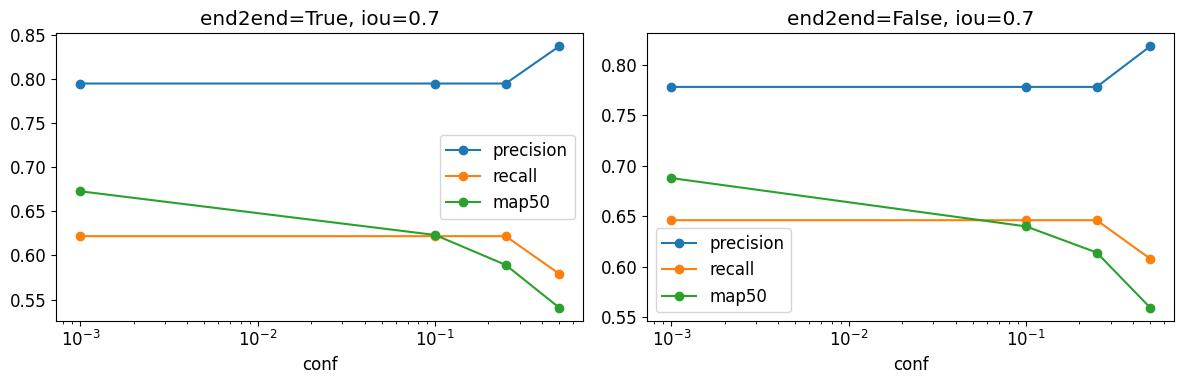

In [35]:
if '6.5' in BONUS_TASKS:
    CONF_GRID = (0.001, 0.1, 0.25, 0.5)
    IOU_GRID = (0.5, 0.7)
    THRESHOLDS = []
    for end2end in (True, False):
        # свежая модель: после первого end2end-прогона fuse() выкидывает ветку one2many, и end2end=False падает
        thresholds_model = YOLO(run_dir / 'weights' / 'best.pt')
        for conf in CONF_GRID:
            for iou in IOU_GRID:
                result = val_at(thresholds_model, IMGSZ, 'thresholds', conf=conf, iou=iou, end2end=end2end)
                THRESHOLDS.append(dict(end2end=end2end, conf=conf, iou=iou, precision=float(result.box.mp),
                                       recall=float(result.box.mr), map50=float(result.box.map50), map50_95=float(result.box.map)))
    print(f'{"end2end":>8} {"conf":>6} {"iou":>4} {"P":>6} {"R":>6} {"mAP50":>6} {"mAP50-95":>9}')
    for row in THRESHOLDS:
        print(f'{str(row["end2end"]):>8} {row["conf"]:>6} {row["iou"]:>4} {row["precision"]:>6.3f} {row["recall"]:>6.3f} '
              f'{row["map50"]:>6.3f} {row["map50_95"]:>9.3f}')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, end2end in zip(axes, (True, False)):
        for metric in ('precision', 'recall', 'map50'):
            rows = [r for r in THRESHOLDS if r['end2end'] == end2end and r['iou'] == 0.7]
            ax.plot([r['conf'] for r in rows], [r[metric] for r in rows], marker='o', label=metric)
        ax.set(xscale='log', xlabel='conf', title=f'end2end={end2end}, iou=0.7')
        ax.legend()
    plt.tight_layout()
    plt.show()

**Ответ:** Взял бы conf около 0.25. P и R одинаковы при conf 0.001, 0.1 и 0.25 и меняются при 0.5, значит максимум F1 между 0.25 и 0.5; для мониторинга свалок пропуск хуже лишнего бокса, поэтому беру нижнюю границу.

mAP здесь как раз заметно зависит от conf: 0.673 при 0.001, 0.623 при 0.1, 0.589 при 0.25, 0.541 при 0.5. mAP - площадь под PR-кривой, а порог conf отрезает ее хвост с низкими score. У нас там много правильных боксов (на PR-кривой test recall доходит до ~0.85 только за счет них); у уверенной модели хвост почти пустой, поэтому обычно mAP от conf почти не зависит. P и R ultralytics печатает в точке максимума F1, поэтому они стоят на месте, пока conf ниже этой точки, а при 0.5 она отрезана (P 0.837, R 0.579).

В end-to-end режиме iou не влияет: строки при 0.5 и 0.7 совпадают, NMS нет. С `end2end=False` (one2many + NMS) mAP50 0.688 против 0.673, и iou уже влияет: R 0.659 при 0.5 и 0.646 при 0.7.